# LDPC: how redundancy pulls bits out of the noise

We send $k$ information bits in $n>k$ channel symbols, rate $R=k/n$. Every codeword $\mathbf c$ satisfies $m=n-k$ parity checks:
$$H\,\mathbf c^T=\mathbf 0 \pmod 2$$
$H$ is **sparse** (Low-Density Parity-Check): every column has $d_v$ ones, every row has $d_c$. Here we use a regular Gallager code $(d_v,d_c)=(3,6)$, $R=1-d_v/d_c=1/2$.

**Channel.** BPSK $x=1-2c$, $y=x+n$, $n\sim\mathcal N(0,\sigma^2)$, $\sigma^2=\dfrac{1}{2R\,E_b/N_0}$. The receiver doesn't slice $y$ by sign; it computes the log-likelihood ratio:
$$L_\text{ch}=\ln\frac{P(c=0\,|\,y)}{P(c=1\,|\,y)}=\frac{2y}{\sigma^2}$$
The sign is the decision, the magnitude is the confidence. For $x=+1$: $L_\text{ch}\sim\mathcal N(\mu,\,2\mu)$, $\mu=2/\sigma^2$, so a single parameter describes everything.

**The decoder** passes messages along the Tanner graph (bits ↔ checks), i.e. belief propagation:
- bit → check: $L_{v\to c}=L_\text{ch}+\sum_{c'\ne c}L_{c'\to v}$. Independent evidence **adds up**;
- check → bit: $\tanh\dfrac{L_{c\to v}}{2}=\prod_{v'\ne v}\tanh\dfrac{L_{v'\to c}}{2}$. The bit equals the XOR of the others, and an XOR is **no more reliable than its weakest input**. The min-sum simplification: $L_{c\to v}\approx\alpha\prod\operatorname{sign}\cdot\min|L|$.

After $\ell$ iterations, up to $[(d_v-1)(d_c-1)]^\ell$ other symbols contribute to the decision on a bit. **Their noise is independent, but the constraints are shared.** This is the same averaging as CDMA despreading, but with a redundancy of only $1/R=2$ instead of $N=1023$.

**Limits at $R=1/2$:** Shannon for BPSK is $E_b/N_0>0.19$ dB; the regular (3,6) threshold is ≈1.1 dB; uncoded BER $10^{-5}$ costs 9.6 dB. Optimized irregular LDPC codes (DVB-S2, Wi-Fi, 5G NR) come within 0.1–0.5 dB of Shannon.

All parameters are in the cell below; everything else is recomputed from them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import erfc
from scipy.optimize import brentq

%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

SEED = 1
N_CODE = 1008      # codeword length (multiple of DC)
DV, DC = 3, 6      # each bit is in DV checks, each check covers DC bits → R = 1 − DV/DC
EBN0_DB = 1.5      # operating point for sections 2–4 (the (3,6) threshold is ≈ 1.1 dB)
MAX_ITER = 50
ALPHA_MS = 0.8     # min-sum normalization

rng = np.random.default_rng(SEED)

## Primitives: H matrix, GF(2) encoder, BP decoder, channel, J-function

In [2]:
def gallager_H(n, dv, dc, rng, fix_4cycles=True, max_fix=20000):
    """Regular (dv,dc) Gallager matrix: dv bands, each a column permutation of the base band."""
    mb = n // dc
    base = np.zeros((mb, n), np.int32)
    for i in range(mb):
        base[i, i * dc:(i + 1) * dc] = 1
    perms = [np.arange(n)] + [rng.permutation(n) for _ in range(dv - 1)]
    build = lambda: np.vstack([base[:, p] for p in perms])
    H = build()
    for _ in range(max_fix if fix_4cycles else 0):
        Hf = H.astype(np.float32)
        O = np.triu(Hf @ Hf.T, 1)
        bad = np.argwhere(O > 1)                  # two checks share ≥2 bits → a 4-cycle
        if len(bad) == 0:
            break
        r1, r2 = bad[rng.integers(len(bad))]
        j = rng.choice(np.nonzero(H[r1] & H[r2])[0])
        b, k = r2 // mb, rng.integers(n)          # r2 is in band ≥1: rows of one band never overlap
        perms[b][[j, k]] = perms[b][[k, j]]
        H = build()
    return H


def count_4cycles(H):
    Hf = H.astype(np.float32)
    O = np.triu(Hf @ Hf.T, 1).astype(np.int64)
    return int(np.sum(O * (O - 1) // 2))


def gf2_rref(H):
    """Row-reduce H over GF(2). Returns A, pivot columns (parity bits), the rest (information bits)."""
    A = H.astype(np.uint8).copy()
    m, n = A.shape
    piv, r = [], 0
    for c in range(n):
        if r == m:
            break
        nz = np.nonzero(A[r:, c])[0]
        if len(nz) == 0:
            continue
        p = r + nz[0]
        A[[r, p]] = A[[p, r]]
        rows = np.nonzero(A[:, c])[0]
        A[rows[rows != r]] ^= A[r]
        piv.append(c)
        r += 1
    return A[:r], np.array(piv), np.setdiff1d(np.arange(n), piv)


def loo_prod(t):
    """Leave-one-out product along the last axis, via prefixes and suffixes (no division by ~0)."""
    one = np.ones_like(t[..., :1])
    pre = np.cumprod(np.concatenate([one, t[..., :-1]], -1), -1)
    suf = np.cumprod(np.concatenate([one, t[..., :0:-1]], -1), -1)[..., ::-1]
    return pre * suf


class LDPC:
    def __init__(self, H):
        self.H = H.astype(np.int32)
        self.m, self.n = H.shape
        r, c = np.nonzero(H)                      # Tanner graph edges, ordered by check
        self.E = len(c)
        self.ev = c                               # bit at the end of each edge
        self.dc = self.E // self.m
        self.var = np.argsort(c, kind="stable").reshape(self.n, -1)   # edges of each bit
        self.A, self.piv, self.info = gf2_rref(H)
        self.k = len(self.info)
        self.R = self.k / self.n
        self.P = self.A[:, self.info].astype(np.int32)

    def encode(self, U):
        C = np.zeros((U.shape[0], self.n), np.uint8)
        C[:, self.info] = U
        C[:, self.piv] = (U @ self.P.T) % 2       # row i of the reduced H: c[piv_i] = Σ A[i,info]·u
        return C

    def syndrome_ok(self, Ch):
        return ~((Ch.astype(np.int32) @ self.H.T) % 2).any(1)

    def decode(self, Lch, iters=50, algo="spa", alpha=0.8, cb=None):
        """BP decoder with early stopping: a frame with zero syndrome is frozen.
        cb(it, Lv, Lcv) is an observer that receives all frames at every iteration."""
        F = Lch.shape[0]
        Lv, Lcv = Lch.astype(float).copy(), np.zeros((F, self.E))
        n_it = np.full(F, iters)
        act = np.arange(F)                        # indices of frames that haven't converged yet
        for it in range(iters + 1):
            La = Lch[act] + Lcv[act][:, self.var].sum(-1)   # a-posteriori LLR of each bit
            Lv[act] = La
            if cb is not None:
                cb(it, Lv, Lcv)
            ok = self.syndrome_ok((La < 0).astype(np.uint8))
            n_it[act[ok]] = it
            act, La = act[~ok], La[~ok]
            if len(act) == 0 or it == iters:
                break
            f = len(act)
            Lvc = (La[:, self.ev] - Lcv[act]).reshape(f, self.m, self.dc)   # bit → check (extrinsic)
            if algo == "spa":
                t = loo_prod(np.tanh(np.clip(Lvc, -40, 40) / 2))
                new = 2 * np.arctanh(np.clip(t, -1 + 1e-12, 1 - 1e-12))
            else:                                  # normalized min-sum
                s = np.where(Lvc < 0, -1.0, 1.0)
                a = np.abs(Lvc)
                i1 = a.argmin(-1)[..., None]
                m1 = np.take_along_axis(a, i1, -1)
                np.put_along_axis(a, i1, np.inf, -1)
                m2 = a.min(-1, keepdims=True)
                mag = np.where(np.arange(self.dc) == i1, m2, m1)
                new = alpha * s.prod(-1, keepdims=True) * s * mag
            Lcv[act] = new.reshape(f, self.E)
        return (Lv < 0).astype(np.uint8), n_it


def channel(C, ebn0_db, R, rng):
    sigma = np.sqrt(1 / (2 * R * 10 ** (ebn0_db / 10)))
    y = (1 - 2.0 * C) + sigma * rng.standard_normal(C.shape)
    return y, 2 * y / sigma**2, sigma


def mi(L, x):
    """Mutual information between an LLR and a bit x∈{±1}: I = 1 − E[log2(1 + e^{−xL})]."""
    return 1 - np.mean(np.logaddexp(0, -x * L)) / np.log(2)


# J(s): information carried by a Gaussian LLR ~ N(s²/2, s²); all we need for EXIT and the Shannon limit
_t, _w = np.polynomial.hermite.hermgauss(120)
_S = np.linspace(0, 25, 5001)
_J = np.maximum.accumulate([1 - np.sum(_w * np.logaddexp(0, -(s * s / 2 + np.sqrt(2) * s * _t))) / np.sqrt(np.pi) / np.log(2) for s in _S])
J = lambda s: np.interp(s, _S, _J)
Jinv = lambda I: np.interp(I, _J, _S)
sch = lambda ebn0_db, R: np.sqrt(8 * R * 10 ** (ebn0_db / 10))       # σ of the channel LLR: 4/σ² = 8R·Eb/N0

exit_v = lambda Ia, e, R: J(np.sqrt((DV - 1) * Jinv(Ia) ** 2 + sch(e, R) ** 2))   # bit node: LLR variances add
exit_c = lambda Ia: 1 - J(np.sqrt(DC - 1) * Jinv(1 - Ia))                         # check node: duality (approx.)

def de_traj(e, R, iters=3000):
    """Evolution of the information over iterations (Gaussian approximation)."""
    Ic, Iv = [0.0], []
    for _ in range(iters):
        Iv.append(float(exit_v(Ic[-1], e, R)))
        Ic.append(float(exit_c(Iv[-1])))
        if Ic[-1] > 0.9999: break
    return np.array(Ic), np.array(Iv)

def exit_threshold(R, lo=-1.0, hi=4.0):
    for _ in range(30):
        mid = (lo + hi) / 2
        lo, hi = (lo, mid) if de_traj(mid, R)[0][-1] > 0.9999 else (mid, hi)
    return hi

shannon_bpsk = lambda R: brentq(lambda e: J(sch(e, R)) - R, -5, 10)


H = gallager_H(N_CODE, DV, DC, rng)
code = LDPC(H)
TH, SH = exit_threshold(code.R), shannon_bpsk(code.R)
print(f"n = {code.n}, m = {code.m}, rank H = {len(code.piv)}, k = {code.k}, R = {code.R:.4f}, edges = {code.E}")
print(f"Shannon (BPSK, R={code.R:.3f}): {SH:.2f} dB,  EXIT threshold ({DV},{DC}): {TH:.2f} dB")

n = 1008, m = 504, rank H = 502, k = 506, R = 0.5020, edges = 3024
Shannon (BPSK, R=0.502): 0.20 dB,  EXIT threshold (3,6): 1.08 dB


## 1. The code as a graph
Left: a toy (3,6) code on 12 bits. Circles are bits, squares are checks, and an edge is a one in $H$. Red shows who bit 0 "hears" in one iteration: 3 checks × 5 neighbours = 15 symbols. In a small code the neighbours repeat. These are **short cycles**: information comes back to the bit and gets counted twice, so BP is no longer exact. In the large code, 4-cycles are removed by construction, and a bit's neighbourhood stays almost a tree for several iterations.

Right: the full $H$. It has three bands, each a column permutation of a "staircase". The rows of each band sum to the all-ones vector, so $\operatorname{rank}H=m-(d_v-1)$ and $R$ is slightly above 1/2.

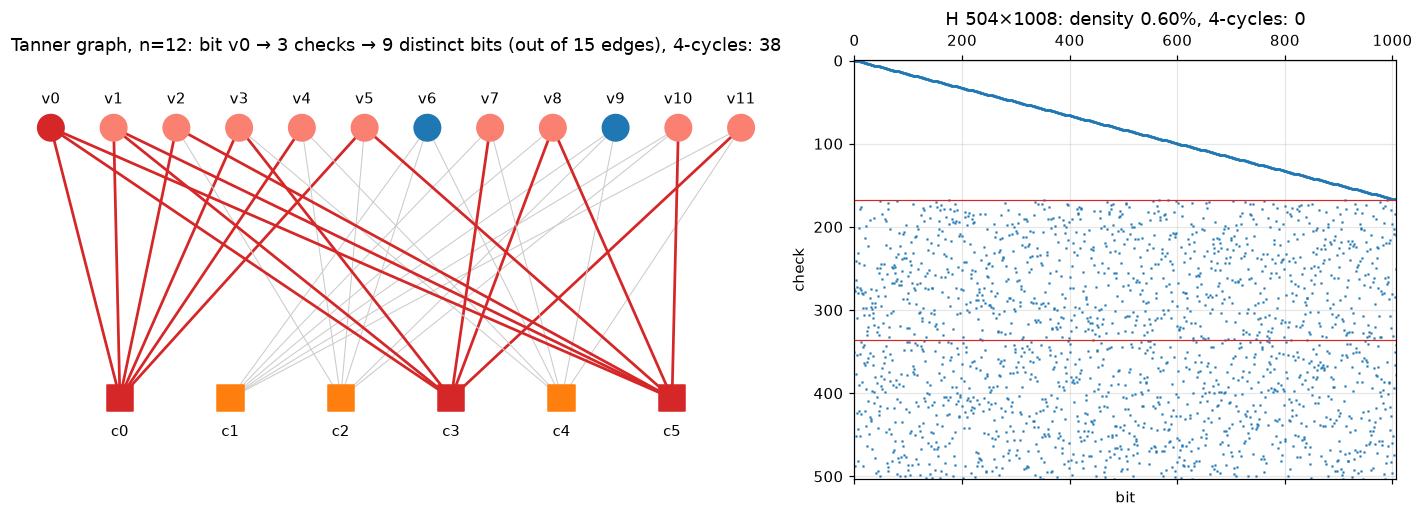

Encoder: H·cᵀ = 0 for random words — True


In [3]:
Ht = gallager_H(12, DV, DC, np.random.default_rng(3), fix_4cycles=False)
mt, nt = Ht.shape
xv, xc = np.linspace(0, 1, nt), np.linspace(0.1, 0.9, mt)
hot_chk = np.nonzero(Ht[:, 0])[0]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8), gridspec_kw={"width_ratios": [1.4, 1]})
a = ax[0]
for i, j in zip(*np.nonzero(Ht)):
    hot = i in hot_chk
    a.plot([xv[j], xc[i]], [1, 0], color="C3" if hot else "0.8", lw=1.8 if hot else 0.7, zorder=1)
heard = np.nonzero(Ht[hot_chk].any(0))[0]
a.scatter(xv, np.ones(nt), s=300, zorder=2, c=["C3" if j == 0 else ("salmon" if j in heard else "C0") for j in range(nt)])
a.scatter(xc, np.zeros(mt), s=300, marker="s", c=["C3" if i in hot_chk else "C1" for i in range(mt)], zorder=2)
for j in range(nt): a.text(xv[j], 1.09, f"v{j}", ha="center")
for i in range(mt): a.text(xc[i], -0.14, f"c{i}", ha="center")
a.set_ylim(-0.3, 1.25); a.axis("off")
a.set_title(f"Tanner graph, n=12: bit v0 → {len(hot_chk)} checks → {len(heard) - 1} distinct bits (out of 15 edges), 4-cycles: {count_4cycles(Ht)}")

ax[1].spy(H, markersize=0.4, aspect="auto")
for b in range(1, DV): ax[1].axhline(b * code.m / DV - 0.5, color="C3", lw=0.8)
ax[1].set_title(f"H {code.m}×{code.n}: density {H.mean():.2%}, 4-cycles: {count_4cycles(H)}")
ax[1].set_xlabel("bit"); ax[1].set_ylabel("check")
plt.tight_layout(); plt.show()

U = rng.integers(0, 2, (5, code.k))
print("Encoder: H·cᵀ = 0 for random words —", code.syndrome_ok(code.encode(U)).all())

## 2. Channel → LLR
At $E_b/N_0$ = `EBN0_DB`, each symbol gets $E_s/N_0=R\,E_b/N_0$, noticeably below 0 dB. A hard sign decision is wrong on roughly every 8th symbol. Right: the LLR multiplied by the transmitted sign, so correct decisions are to the right of zero and errors to the left. The Gaussian $\mathcal N(\mu,2\mu)$ is the theory.

The key number is **how much information about a bit one symbol carries**, $I=J(\sqrt{8RE_b/N_0})$. If $I>R$, a code can in principle fix everything (Shannon); if $I<R$, no decoder can help.

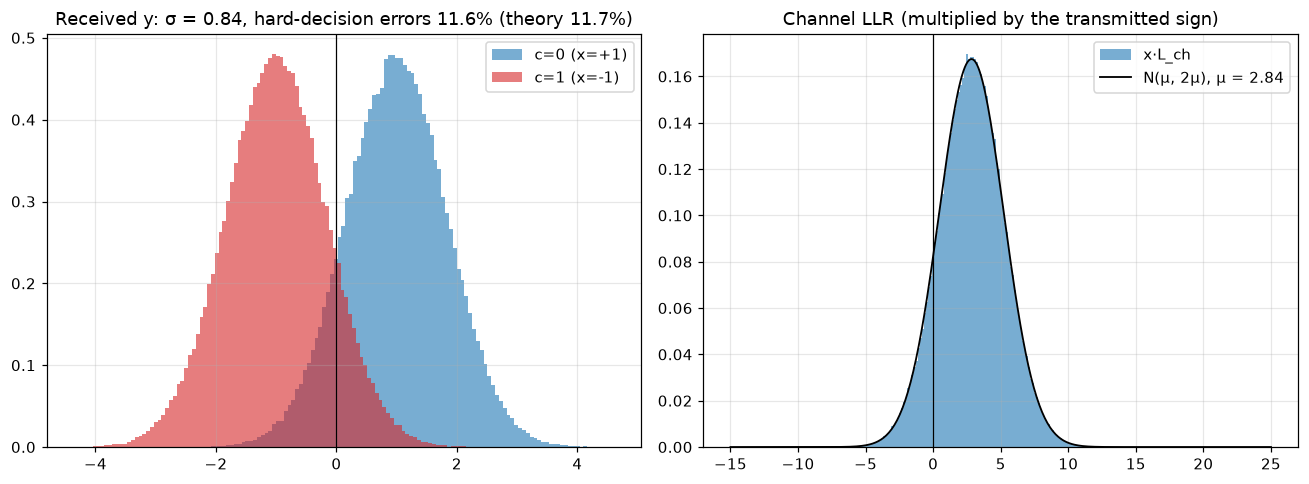

Information per symbol: measured 0.604 bit, theory J(σ_ch) = 0.604 bit, need R = 0.502 bit → there is margin


In [4]:
U = rng.integers(0, 2, (400, code.k))
C = code.encode(U); X = 1 - 2.0 * C
y, L, sigma = channel(C, EBN0_DB, code.R, rng)
mu = 2 / sigma**2

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for c, col in [(0, "C0"), (1, "C3")]:
    ax[0].hist(y[C == c], 120, density=True, alpha=0.6, color=col, label=f"c={c} (x={1-2*c:+d})")
ax[0].axvline(0, color="k", lw=0.8); ax[0].legend()
ax[0].set_title(f"Received y: σ = {sigma:.2f}, hard-decision errors {np.mean((y < 0) != C):.1%} "
                f"(theory {0.5*erfc(np.sqrt(code.R*10**(EBN0_DB/10))):.1%})")
l = np.linspace(-15, 25, 400)
ax[1].hist((L * X).ravel(), 150, density=True, alpha=0.6, label="x·L_ch")
ax[1].plot(l, np.exp(-(l - mu)**2 / (4 * mu)) / np.sqrt(4 * np.pi * mu), "k", lw=1.2, label=f"N(μ, 2μ), μ = {mu:.2f}")
ax[1].axvline(0, color="k", lw=0.8); ax[1].legend()
ax[1].set_title("Channel LLR (multiplied by the transmitted sign)")
plt.tight_layout(); plt.show()

print(f"Information per symbol: measured {mi(L, X):.3f} bit, theory J(σ_ch) = {J(sch(EBN0_DB, code.R)):.3f} bit, "
      f"need R = {code.R:.3f} bit → {'there is margin' if J(sch(EBN0_DB, code.R)) > code.R else 'NO margin'}")

## 3. Iterations from the inside
100 frames at `EBN0_DB`. Left: how many bits in each frame are wrong after each iteration. Errors vanish **like an avalanche**. While there are few reliable bits, the checks give almost nothing. Once there are enough, they pull their neighbours through the checks, and those pull theirs. Some frames never converge; that is the FER at this code length.

Right: the distribution of the a-posteriori $x\cdot L$ over iterations. The mass moves right, and confidence grows by orders of magnitude.

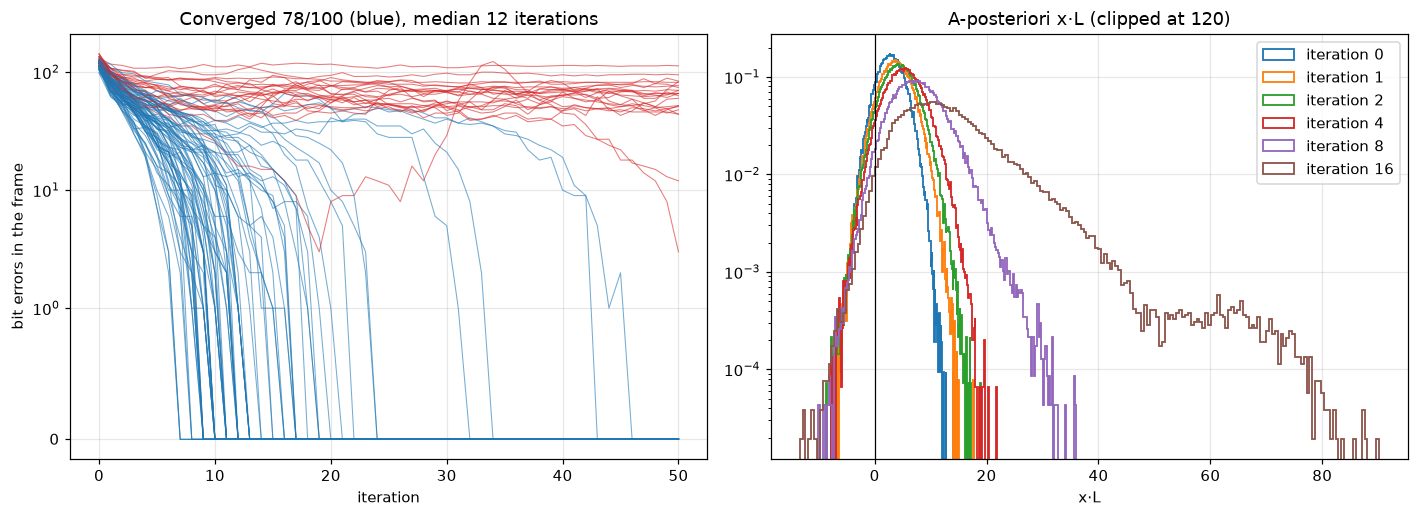

Channel errors (before decoding): 118 bits per frame out of 1008 (11.7%)
After decoding: BER = 1.34e-02, FER = 0.22


In [5]:
F = 100
U = rng.integers(0, 2, (F, code.k))
C = code.encode(U); X = 1 - 2.0 * C; Xe = X[:, code.ev]
_, L, _ = channel(C, EBN0_DB, code.R, rng)
hist = []
def rec(it, Lv, Lcv):
    hist.append(dict(xL=(Lv * X).astype(np.float32), err=(Lv * X < 0).sum(1),
                     Icv=mi(Lcv, Xe), Ivc=mi(Lv[:, code.ev] - Lcv, Xe)))
Ch, nit = code.decode(L, MAX_ITER, "spa", cb=rec)
conv = code.syndrome_ok(Ch)
E = np.array([h["err"] for h in hist])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for f in range(F):
    ax[0].plot(E[:, f], color="C0" if conv[f] else "C3", lw=0.7, alpha=0.6)
ax[0].set_yscale("symlog", linthresh=1); ax[0].set_xlabel("iteration"); ax[0].set_ylabel("bit errors in the frame")
ax[0].set_title(f"Converged {conv.sum()}/{F} (blue), median {np.median(nit[conv]):.0f} iterations")
for it in [0, 1, 2, 4, 8, 16]:
    if it < len(hist):
        ax[1].hist(np.clip(hist[it]["xL"].ravel(), -20, 120), 200, density=True, histtype="step", lw=1.2, label=f"iteration {it}")
ax[1].set_yscale("log"); ax[1].axvline(0, color="k", lw=0.8); ax[1].legend()
ax[1].set_title("A-posteriori x·L (clipped at 120)"); ax[1].set_xlabel("x·L")
plt.tight_layout(); plt.show()

print(f"Channel errors (before decoding): {E[0].mean():.0f} bits per frame out of {code.n} ({E[0].mean()/code.n:.1%})")
print(f"After decoding: BER = {np.mean(Ch[:, code.info] != U):.2e}, FER = {1 - conv.mean():.2f}")

## 4. The threshold: EXIT chart
If the edge messages are Gaussian LLRs, each one is described by a single number: its mutual information $I$ with the bit. The bit node and the check node then become two transfer functions $I_\text{out}=f(I_\text{in})$, and the decoder walks between them like a staircase.

- **Bit node**: LLRs add, and so do their variances: $I_{E,V}=J\big(\sqrt{(d_v-1)\,J^{-1}(I_A)^2+\sigma_\text{ch}^2}\big)$. **Only this curve** depends on the channel.
- **Check node**: $I_{E,C}\approx1-J\big(\sqrt{d_c-1}\,J^{-1}(1-I_A)\big)$.

As long as there is a **tunnel** between the curves, the staircase reaches $I=1$ (error-free as $n\to\infty$). The threshold is the $E_b/N_0$ at which the tunnel closes. Left: below the threshold. Right: the operating point, with dots measured in the section 3 simulation. The simulation follows the theory for the first steps and then falls behind: on a finite graph, a bit's neighbourhood closes into cycles after ~5 iterations, messages stop being independent, and frames that didn't converge drag the average down.

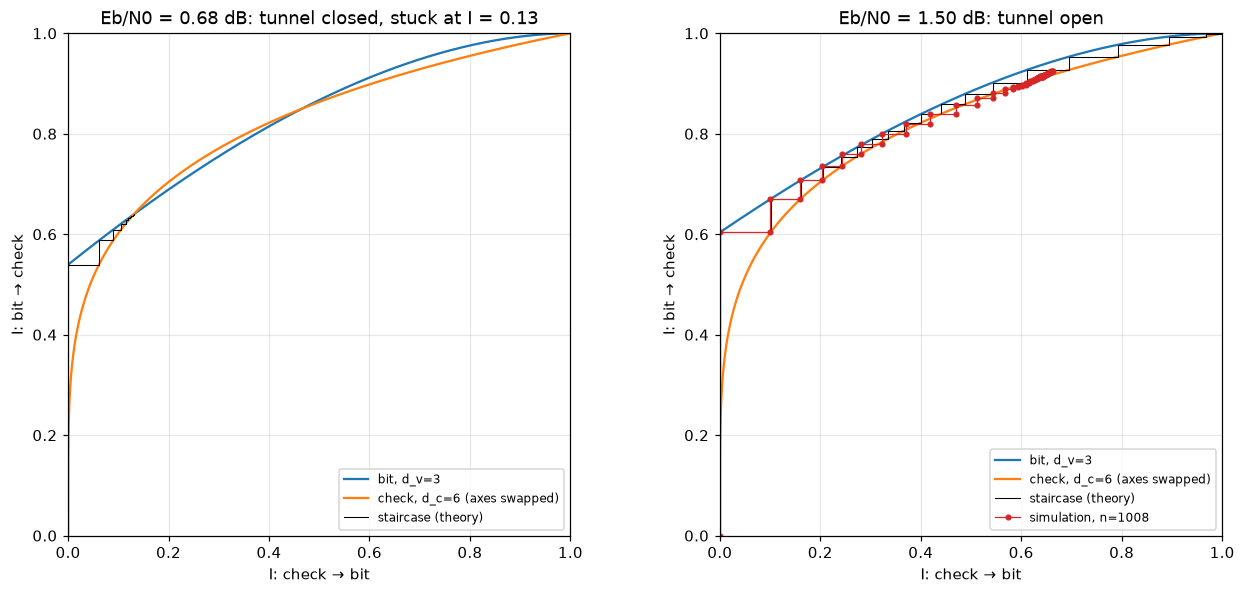

EXIT threshold: 1.08 dB (exact density evolution for (3,6): 1.11 dB), Shannon: 0.20 dB — the regular code loses 0.9 dB; irregular degree distributions fit the two curves to each other.


In [6]:
def stairs(Ic, Iv):
    xs, ys = [Ic[0]], [0.0]
    for l in range(len(Iv)):
        xs += [Ic[l], Ic[l + 1]]; ys += [Iv[l], Iv[l]]
    return xs, ys

Ia = np.linspace(0, 1, 401)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.5))
for a, e in zip(ax, [TH - 0.4, EBN0_DB]):
    a.plot(Ia, exit_v(Ia, e, code.R), "C0", lw=1.5, label=f"bit, d_v={DV}")
    a.plot(exit_c(Ia), Ia, "C1", lw=1.5, label=f"check, d_c={DC} (axes swapped)")
    Ic, Iv = de_traj(e, code.R, 300)
    a.plot(*stairs(Ic, Iv), "k", lw=0.7, label="staircase (theory)")
    st = "open" if Ic[-1] > 0.9999 else f"closed, stuck at I = {Ic[-1]:.2f}"
    a.set_title(f"Eb/N0 = {e:.2f} dB: tunnel {st}")
    a.set_xlabel("I: check → bit"); a.set_ylabel("I: bit → check"); a.set_xlim(0, 1); a.set_ylim(0, 1); a.set_aspect("equal")
Icv, Ivc = np.array([h["Icv"] for h in hist]), np.array([h["Ivc"] for h in hist])
ax[1].plot(*stairs(Icv, Ivc[:-1]), "C3o-", ms=3, lw=0.8, label="simulation, n=%d" % code.n)
for a in ax: a.legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.show()

print(f"EXIT threshold: {TH:.2f} dB (exact density evolution for (3,6): 1.11 dB), Shannon: {SH:.2f} dB — "
      f"the regular code loses {TH - SH:.1f} dB; irregular degree distributions fit the two curves to each other.")

## 5. The waterfall: BER/FER vs. Eb/N0
Sum-product (exact BP) and normalized min-sum (what goes into hardware: only comparisons and additions). The dashed lines are the Shannon limit and the EXIT threshold. The threshold is the $n\to\infty$ asymptote; at finite length the waterfall shifts right. Right: average decoding time. At higher SNR the decoder converges in a few iterations.

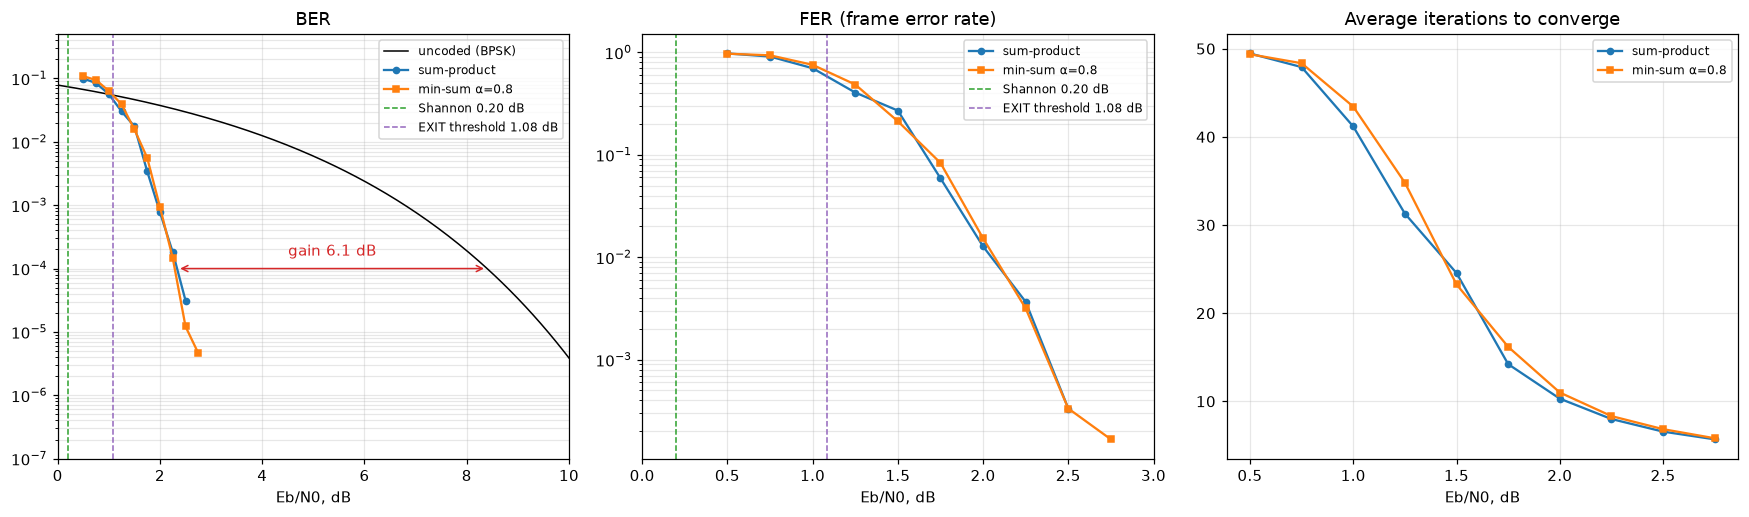

 Eb/N0 |  BER SPA   FER SPA  iter |  BER MS    FER MS   iter | frames SPA
  0.50 |  1.0e-01  9.7e-01  49.5 |  1.1e-01  9.7e-01  49.4 | 200
  0.75 |  8.5e-02  9.1e-01  47.9 |  9.4e-02  9.4e-01  48.4 | 200
  1.00 |  5.7e-02  7.0e-01  41.2 |  6.3e-02  7.6e-01  43.4 | 200
  1.25 |  3.0e-02  4.1e-01  31.3 |  3.9e-02  4.8e-01  34.8 | 200
  1.50 |  1.8e-02  2.7e-01  24.5 |  1.6e-02  2.1e-01  23.3 | 200
  1.75 |  3.4e-03  5.9e-02  14.2 |  5.6e-03  8.3e-02  16.2 | 1000
  2.00 |  7.7e-04  1.3e-02  10.3 |  9.4e-04  1.5e-02  11.0 | 4000
  2.25 |  1.8e-04  3.7e-03   8.0 |  1.5e-04  3.2e-03   8.3 | 6000
  2.50 |  3.1e-05  3.3e-04   6.6 |  1.2e-05  3.3e-04   6.8 | 6000
  2.75 |  0.0e+00  0.0e+00   5.7 |  4.6e-06  1.7e-04   5.8 | 6000

BER = 1e-04: uncoded 8.4 dB, LDPC 2.3 dB → coding gain 6.1 dB at the cost of twice the bandwidth (R = 1/2)


In [7]:
def simulate(ebn0_list, algo, min_fe=50, max_frames=6000, batch=200):
    res = []
    for e in ebn0_list:
        be = fe = nf = its = 0
        while fe < min_fe and nf < max_frames:
            U = rng.integers(0, 2, (batch, code.k))
            _, L, _ = channel(code.encode(U), e, code.R, rng)
            Ch, nit = code.decode(L, MAX_ITER, algo, ALPHA_MS)
            err = Ch[:, code.info] != U
            be += err.sum(); fe += err.any(1).sum(); nf += batch; its += nit.sum()
        res.append((be / (nf * code.k), fe / nf, its / nf, nf))
    return np.array(res)

ebn0 = np.arange(0.5, 2.76, 0.25)
res = {"sum-product": simulate(ebn0, "spa"), f"min-sum α={ALPHA_MS}": simulate(ebn0, "ms")}

r = res["sum-product"]
target = 1e-4                                      # below this the statistics are thin (0 errors in 6000 frames ≠ BER 0)
i = np.argmax((r[:, 0] < target) & (r[:, 0] > 0))  # first non-zero point below target, interpolate in log BER
e_code = np.interp(np.log10(target), np.log10(r[[i, i - 1], 0]), ebn0[[i, i - 1]])
e_unc = brentq(lambda e: 0.5 * erfc(np.sqrt(10 ** (e / 10))) - target, 0, 15)

eb = np.linspace(0, 10, 200)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
ax[0].semilogy(eb, 0.5 * erfc(np.sqrt(10 ** (eb / 10))), "k-", lw=1, label="uncoded (BPSK)")
for (name, rr), mk in zip(res.items(), "os"):
    ok = rr[:, 0] > 0
    ax[0].semilogy(ebn0[ok], rr[ok, 0], mk + "-", ms=4, label=name)
    ax[1].semilogy(ebn0[rr[:, 1] > 0], rr[rr[:, 1] > 0, 1], mk + "-", ms=4, label=name)
    ax[2].plot(ebn0, rr[:, 2], mk + "-", ms=4, label=name)
for a in ax[:2]:
    a.axvline(SH, color="C2", ls="--", lw=1, label=f"Shannon {SH:.2f} dB")
    a.axvline(TH, color="C4", ls="--", lw=1, label=f"EXIT threshold {TH:.2f} dB")
ax[0].annotate("", xy=(e_code, target), xytext=(e_unc, target), arrowprops=dict(arrowstyle="<->", color="C3"))
ax[0].text((e_code + e_unc) / 2, target * 1.6, f"gain {e_unc - e_code:.1f} dB", color="C3", ha="center")
ax[0].set_xlim(0, 10); ax[0].set_ylim(1e-7, 0.5)
ax[1].set_xlim(0, 3)
ax[0].set_title("BER"); ax[1].set_title("FER (frame error rate)"); ax[2].set_title("Average iterations to converge")
for a in ax: a.set_xlabel("Eb/N0, dB"); a.legend(fontsize=8); a.grid(which="both", alpha=0.3)
plt.tight_layout(); plt.show()

print(" Eb/N0 |  BER SPA   FER SPA  iter |  BER MS    FER MS   iter | frames SPA")
for i, e in enumerate(ebn0):
    s, q = list(res.values())[0][i], list(res.values())[1][i]
    print(f" {e:5.2f} | {s[0]:8.1e} {s[1]:8.1e} {s[2]:5.1f} | {q[0]:8.1e} {q[1]:8.1e} {q[2]:5.1f} | {int(s[3])}")

print(f"\nBER = {target:.0e}: uncoded {e_unc:.1f} dB, LDPC {e_code:.1f} dB → coding gain {e_unc - e_code:.1f} dB "
      f"at the cost of twice the bandwidth (R = 1/2)")

## Comparison with CDMA
DSSS from the CDMA notebook is also a code: a **repetition code** with rate $R=1/N$, where each bit is simply repeated $N$ times. Against white noise it gives nothing (the curve is BPSK): the bit energy is the same, just smeared over $N$ chips. LDPC at $R=1/2$ gives 6–7 dB. Its parity bits don't copy the data, they **tie it together**, so every error has to "break through" several independent constraints.

| | DSSS (repetition) | LDPC (3,6) |
|---|---|---|
| Redundancy | $N=1023$ | 2 |
| Gain against AWGN (BER $10^{-4}$…$10^{-5}$) | 0 dB | 6–7 dB |
| Against narrowband interference | $10\log_{10}N$ = 30 dB | ~0 (needs an interleaver) |
| Decoder | a single correlator | iterative LLR exchange |

Real systems use both: spreading/OFDM deals with the channel, the code with the residual noise. LTE encodes data with a turbo code (the same iterative LLR exchange, but two convolutional codes instead of a graph). LDPC arrived in 5G NR and Wi-Fi as quasi-cyclic matrices, built from cyclic shifts of $Z\times Z$ identity blocks so that the decoder can run in parallel.

## Things to try
- `EBN0_DB = 1.0`: below the threshold. In section 4 the tunnel is closed, and in section 3 almost every frame gets stuck with about a hundred errors
- `N_CODE = 96` / `4032`: the waterfall gets steeper with length and moves toward the EXIT threshold; the threshold itself doesn't change
- `DV, DC = 4, 8` (same $R=1/2$): a worse threshold (~1.5 dB). More edges mean more constraints, but each is weaker
- `ALPHA_MS = 1.0`: plain min-sum overestimates check confidence ($\min|L|$ is larger than the exact value) and loses noticeably; the normalization compensates. At high SNR normalized min-sum can even beat exact BP: on a graph with cycles, BP itself is overconfident
- `gallager_H(..., fix_4cycles=False)`: keep the 4-cycles and watch the erroneous "echo" in BP